# String Model Fit of Knotted-Ring Polymer Melts

Mass-dependent string-model analysis for knot types $3_1$ through $9_1$ at
$T=1.0\varepsilon/k_{\mathrm B}$, under constant-volume and constant-pressure conditions.
These are the simulation observables used for Supplementary Fig. S6.

$$\tau_\alpha(M)=\tau_o\exp[A z(M)],\qquad z(M)=L(M)/L_M,$$
$$\ln\tau_\alpha(M)=\ln\tau_M+A[z(M)-1],\qquad \tau_o=\tau_M e^{-A}.$$

Here $L_M$ and $\tau_M$ are evaluated at a fixed mass-reference state for each
knot type and ensemble. They are **not** temperature-onset quantities $L_A$ and $\tau_A$.
Each fit has one free parameter, $A=\Delta G_o/(k_{\mathrm B}T)$.
A fixed-temperature fit does not separate activation enthalpy and entropy.

In [1]:
from pathlib import Path
import numpy as np
from scipy.optimize import curve_fit

MCList = np.arange(3, 10)
N = len(MCList)
List = [f"MC{mc:02d}" for mc in MCList]
Ensembles = ["ConstV", "ConstP"]
Tset = 1.0  # nominal temperature in epsilon/k_B

# Run from the notebook directory, or from the repository root.
FIT_DIR = Path.cwd()
if not (FIT_DIR / "Data" / "ConstV").is_dir():
    FIT_DIR = FIT_DIR / "String_model_fit"
if not (FIT_DIR / "Data" / "ConstV").is_dir():
    raise FileNotFoundError("Run from String_model_fit or the repository root.")

SHOW_REFERENCE = False  # S6 omits the 14 reference markers, not their fit constraints.
PLOT_LIMITS = (10.0, 22.0)  # full view; set (10.0, 20.0) for the original S6 window

## Basic parameters

The original mass-reference parameters are listed in $m_c=3,\ldots,9$ order.
The plain-text input files retain their original numerical contents and aligned rows.
Columns below are counted from one:

- `System`: column 7 gives bead count $M$.
- `Thermo`: column 3 gives measured reduced temperature.
- `Tau010_FSQ`: column 1 gives $\tau_\alpha$ in Lennard–Jones time units, using the 0.1 decay criterion.
- `Peak_ASL`: column 3 gives peak mean string length $L$.

The original S6 fit window is retained: $M<M_{\rm ref}+0.1$ and
$\tau_\alpha<\min(30000,\,3\langle\max_M\tau_\alpha\rangle_{m_c})$, evaluated separately
for each ensemble. All input rows remain in `Data_Collection`; `Fit_Mask` records
the selection. The fits include 93 points, including 14 reference states.
The default plots show all 79 non-reference points. Four constant-pressure points
lie above the original S6 plotting limit of 20, so the default upper limit is 22.

In [2]:
# Fixed mass-reference parameters from the original analysis.
M_ref = {
    "ConstV": np.array([24.0, 28.0, 31.0, 36.0, 40.0, 44.0, 48.0]),
    "ConstP": np.array([24.0, 28.0, 32.0, 36.0, 40.0, 44.0, 48.0]),
}

L_M = {
    "ConstV": np.array([1.4529832, 1.4863702, 1.5428696, 1.5459508, 1.5341848, 1.584972, 1.5786367]),
    "ConstP": np.array([1.3364528, 1.3672314, 1.3769933, 1.4055325, 1.3991691, 1.4418626, 1.4408432]),
}

Tau_M = {
    "ConstV": np.array([4.95175722, 7.04903631, 9.13032013, 11.3560709, 10.5526977, 15.2556599, 12.9624133]),
    "ConstP": np.array([1.98229518, 2.60886406, 2.47811096, 3.38084452, 3.12406226, 4.44328884, 3.96820295]),
}


# Data columns: M, tau_alpha, z=L/L_M, ln(tau_alpha), measured T.
Data_Collection = {ensemble: [] for ensemble in Ensembles}
Data_Fit_Collection = {ensemble: [] for ensemble in Ensembles}
Fit_Mask = {ensemble: [] for ensemble in Ensembles}
Tau_Upper = {}

for ensemble in Ensembles:
    for i, name in enumerate(List):
        folder = FIT_DIR / "Data" / ensemble / name
        System = np.loadtxt(folder / "System", ndmin=2)
        Thermo = np.loadtxt(folder / "Thermo", ndmin=2)
        TauData = np.loadtxt(folder / "Tau010_FSQ", ndmin=2)
        StringData = np.loadtxt(folder / "Peak_ASL", ndmin=2)
        arrays = (System, Thermo, TauData, StringData)
        if len({len(array) for array in arrays}) != 1:
            raise ValueError(f"Unaligned input rows: {ensemble}/{name}")
        if not all(np.isfinite(array).all() for array in arrays):
            raise ValueError(f"Non-finite input: {ensemble}/{name}")

        Mass, Temp = System[:, 6], Thermo[:, 2]
        Tau, ASL = TauData[:, 0], StringData[:, 2]
        if len(np.unique(Mass)) != len(Mass) or not np.all(Mass == np.round(Mass)):
            raise ValueError(f"Expected unique integer bead counts: {ensemble}/{name}")
        if not (np.all(Tau > 0) and np.all(ASL > 0) and np.all(Mass > 0)):
            raise ValueError(f"Nonpositive input: {ensemble}/{name}")
        if not np.allclose(Temp, Tset, atol=0.005, rtol=0):
            raise ValueError(f"Unexpected temperature: {ensemble}/{name}")

        reference = np.isclose(Mass, M_ref[ensemble][i], atol=1e-9, rtol=0)
        if reference.sum() != 1:
            raise ValueError(f"Missing or duplicate mass-reference state: {ensemble}/{name}")
        np.testing.assert_allclose(ASL[reference], L_M[ensemble][i], rtol=1e-8)
        np.testing.assert_allclose(Tau[reference], Tau_M[ensemble][i], rtol=1e-8)
        Data = np.column_stack((Mass, Tau, ASL / L_M[ensemble][i], np.log(Tau), Temp))
        Data_Collection[ensemble].append(Data)

    Tau_Upper[ensemble] = min(3e4, 3 * np.mean([
        data[:, 1].max() for data in Data_Collection[ensemble]
    ]))
    print(f"{ensemble}: tau upper limit = {Tau_Upper[ensemble]:.8g}")
    for i, data in enumerate(Data_Collection[ensemble]):
        mask = (data[:, 0] < M_ref[ensemble][i] + 0.1) & (data[:, 1] < Tau_Upper[ensemble])
        selected = data[mask]
        if len(selected) < 2 or np.ptp(selected[:, 2]) == 0:
            raise ValueError(f"Insufficient fit data: {ensemble}/{List[i]}")
        Fit_Mask[ensemble].append(mask)
        Data_Fit_Collection[ensemble].append(selected)
        print(f"  mc={MCList[i]}: {len(data)} input, {mask.sum()} fitted, {(~mask).sum()} outside fit window")

ConstV: tau upper limit = 26269.136
  mc=3: 16 input, 6 fitted, 10 outside fit window
  mc=4: 14 input, 6 fitted, 8 outside fit window
  mc=5: 13 input, 6 fitted, 7 outside fit window
  mc=6: 11 input, 6 fitted, 5 outside fit window
  mc=7: 11 input, 6 fitted, 5 outside fit window
  mc=8: 12 input, 7 fitted, 5 outside fit window
  mc=9: 10 input, 7 fitted, 3 outside fit window
ConstP: tau upper limit = 22018.786
  mc=3: 17 input, 7 fitted, 10 outside fit window
  mc=4: 15 input, 7 fitted, 8 outside fit window
  mc=5: 12 input, 6 fitted, 6 outside fit window
  mc=6: 12 input, 7 fitted, 5 outside fit window
  mc=7: 11 input, 6 fitted, 5 outside fit window
  mc=8: 13 input, 8 fitted, 5 outside fit window
  mc=9: 11 input, 8 fitted, 3 outside fit window


## Fit the model under constant volume

Unweighted least squares is applied to $\ln\tau_\alpha$ using the measured $L/L_M$.
The prefactor is constrained by the reference state; it is not an independent fit parameter.

In [3]:
ensemble = "ConstV"
A_V = np.zeros(N)
Tauo_V = np.zeros(N)
for i in range(N):
    Data = Data_Fit_Collection[ensemble][i]
    z, ln_tau = Data[:, 2], Data[:, 3]

    def func(z, A):
        return np.log(Tau_M[ensemble][i]) - A + A * z

    popt, pcov = curve_fit(func, z, ln_tau, p0=[1.0])
    A_V[i] = popt[0]
    Tauo_V[i] = Tau_M[ensemble][i] * np.exp(-A_V[i])

print("mc         A           tau_o [LJ time]")
for mc, A, tauo in zip(MCList, A_V, Tauo_V):
    print(f"{mc:2d}   {A:12.8f}   {tauo:.8e}")

mc         A           tau_o [LJ time]
 3    11.68847253   4.15451395e-05
 4    12.79813739   1.94970677e-05
 5    11.15800342   1.30204708e-04
 6    11.90101852   7.70338178e-05
 7    11.05215970   1.67290595e-04
 8    12.31697730   6.82709152e-05
 9    11.81238927   9.60794227e-05


In [4]:
# Model arrays retain ALL fitted rows: M, A*z, ln(tau_alpha/tau_o).
Model_V = []
X, Y = [], []
for i in range(N):
    Data = Data_Fit_Collection["ConstV"][i]
    X0 = A_V[i] * Data[:, 2]
    Y0 = Data[:, 3] - np.log(Tauo_V[i])
    Model_V.append(np.column_stack((Data[:, 0], X0, Y0)))
    show = np.ones(len(Data), dtype=bool) if SHOW_REFERENCE else ~np.isclose(
        Data[:, 0], M_ref["ConstV"][i], atol=1e-9, rtol=0
    )
    X.append(X0[show])
    Y.append(Y0[show])

### Plot the model

ConstV: 37 plotted points; 0 outside PLOT_LIMITS.


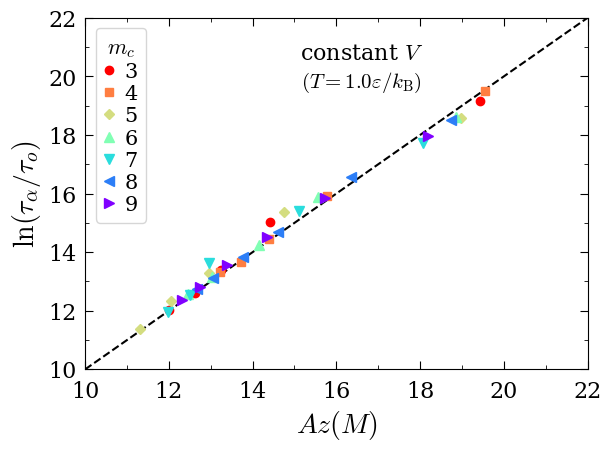

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Preserve the original notebook's serif/rainbow style. Mathtext avoids a LaTeX dependency.
plt.rcParams.update({
    "text.usetex": False, "font.family": "serif", "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "cm", "axes.unicode_minus": False,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
})
# Marker shapes and colors follow the knotted-ring manuscript.
Mark_Type = ["o", "s", "D", "^", "v", "<", ">"]
Mark_Size = [4, 3.5, 3.5, 4.5, 4.5, 4.5, 4.5]
cm = plt.get_cmap("rainbow")

def plot_model(X, Y, ensemble):
    fig, ax = plt.subplots(1, 1, figsize=(6, 4.4), constrained_layout=True)
    ax.tick_params(axis="x", which="major", direction="in", top=True, length=6, pad=8, labelsize=16)
    ax.tick_params(axis="y", which="major", direction="in", right=True, length=6, pad=6, labelsize=16)
    ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True, length=3)
    lo, hi = PLOT_LIMITS
    if not np.isfinite([lo, hi]).all() or lo >= hi:
        raise ValueError("PLOT_LIMITS must be finite and increasing.")
    ax.set(xlim=(lo, hi), ylim=(lo, hi))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(ticker.MultipleLocator(2))
        axis.set_minor_locator(ticker.MultipleLocator(1))

    n_outside = 0
    for i in range(N):
        if not (np.isfinite(X[i]).all() and np.isfinite(Y[i]).all()):
            raise ValueError("Non-finite transformed point.")
        n_outside += np.count_nonzero((X[i] < lo) | (X[i] > hi) | (Y[i] < lo) | (Y[i] > hi))
        ax.plot(X[i], Y[i], Mark_Type[i], ms=1.5 * Mark_Size[i],
                color=cm(1 - i / (N - 1)), label=str(MCList[i]))
    ax.plot([lo, hi], [lo, hi], "--", color="black", linewidth=1.5, zorder=0)
    ax.legend(loc="upper left", ncol=1, labelspacing=0.15, columnspacing=0.2,
              handlelength=0.5, handletextpad=0.5, fontsize=15,
              title=r"$m_c$", title_fontsize=16)
    heading = r"constant $V$" if ensemble == "ConstV" else r"constant $P$"
    ax.text(0.55, 0.93, heading, ha="center", va="top", fontsize=16, transform=ax.transAxes)
    ax.text(0.55, 0.85, r"$(T=1.0\varepsilon/k_{\mathrm{B}})$", ha="center", va="top",
            fontsize=15, transform=ax.transAxes)
    ax.set_xlabel(r"$A z(M)$", fontsize=20)
    ax.set_ylabel(r"$\ln(\tau_\alpha/\tau_o)$", fontsize=20)
    print(f"{ensemble}: {sum(map(len, X))} plotted points; {n_outside} outside PLOT_LIMITS.")
    if n_outside:
        print("Those points remain in the fit and model arrays; use (10, 22) for the full supplied dataset.")
    return fig, ax

fig_V, ax_V = plot_model(X, Y, "ConstV")
plt.show()

## Fit the model under constant pressure

The same one-parameter model and mass-window rule are applied independently
to the constant-pressure data, using their own mass-reference states.

In [6]:
ensemble = "ConstP"
A_P = np.zeros(N)
Tauo_P = np.zeros(N)
for i in range(N):
    Data = Data_Fit_Collection[ensemble][i]
    z, ln_tau = Data[:, 2], Data[:, 3]

    def func(z, A):
        return np.log(Tau_M[ensemble][i]) - A + A * z

    popt, pcov = curve_fit(func, z, ln_tau, p0=[1.0])
    A_P[i] = popt[0]
    Tauo_P[i] = Tau_M[ensemble][i] * np.exp(-A_P[i])

print("mc         A           tau_o [LJ time]")
for mc, A, tauo in zip(MCList, A_P, Tauo_P):
    print(f"{mc:2d}   {A:12.8f}   {tauo:.8e}")

mc         A           tau_o [LJ time]
 3    13.15274576   3.84594812e-06
 4    12.38018310   1.09598913e-05
 5    12.33523673   1.08891882e-05
 6    11.70623466   2.78658362e-05
 7    10.99867296   5.22464401e-05
 8    12.20965957   2.21368983e-05
 9    11.49514822   4.03937745e-05


In [7]:
Model_P = []
X1, Y1 = [], []
for i in range(N):
    Data = Data_Fit_Collection["ConstP"][i]
    X0 = A_P[i] * Data[:, 2]
    Y0 = Data[:, 3] - np.log(Tauo_P[i])
    Model_P.append(np.column_stack((Data[:, 0], X0, Y0)))
    show = np.ones(len(Data), dtype=bool) if SHOW_REFERENCE else ~np.isclose(
        Data[:, 0], M_ref["ConstP"][i], atol=1e-9, rtol=0
    )
    X1.append(X0[show])
    Y1.append(Y0[show])

### Plot the model

ConstP: 42 plotted points; 0 outside PLOT_LIMITS.


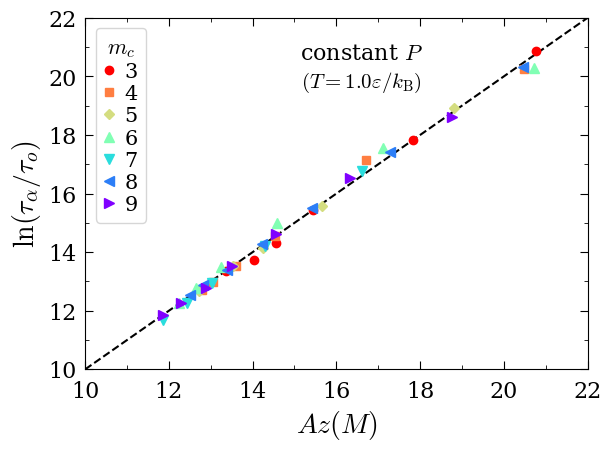

In [8]:
fig_P, ax_P = plot_model(X1, Y1, "ConstP")
plt.show()

# Optional vector/raster export, retaining editable PDF text:
# fig_V.savefig(FIT_DIR / "String_model_ConstV.pdf")
# fig_P.savefig(FIT_DIR / "String_model_ConstP.pdf")
# fig_V.savefig(FIT_DIR / "String_model_ConstV.svg")
# fig_P.savefig(FIT_DIR / "String_model_ConstP.svg")
# fig_V.savefig(FIT_DIR / "String_model_ConstV.png", dpi=300)
# fig_P.savefig(FIT_DIR / "String_model_ConstP.png", dpi=300)